# Week 02: The Maths Behind Machine Learning — Support Notebook

Companion code for the Week 02 slides. Section numbers follow the slide parts.

| Part | Topic |
|---|---|
| 01 | Recap & Environment Check |
| 02 | Linear Algebra for ML |
| 03 | Calculus & Optimization |
| 04 | Probability & Statistics |
| 05 | NumPy & Pandas in Action |

Goal: see the maths inside every ML model, with intuition and code.

## Part 01 — Recap & Setup

ML lifecycle: problem definition → data collection & preparation → **model training** → evaluation → deploy & monitor.
Today's maths lives mostly in model training: how a model learns from data.

### Environment Check (slide 4)

In [43]:
import numpy as np, pandas as pd
print(np.__version__)
print(pd.__version__)

1.26.4
2.3.3


In [44]:
import os
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

if not os.path.exists("houses.csv"):
    pd.DataFrame({
        "size_sqft": [800, 1000, 1200, 1500, 1800, 2200],
        "bedrooms":  [2, 3, 3, 4, 4, 5],
        "price_lkr": [18000000, 22500000, 26000000, 32000000, 38000000, 46000000],
    }).to_csv("houses.csv", index=False)

df = pd.read_csv("houses.csv")
df

,size_sqft,bedrooms,price_lkr
0,800,2,18000000
1,1000,3,22500000
2,1200,3,26000000
3,1500,4,32000000
4,1800,4,38000000
5,2200,5,46000000


## Part 02 — Linear Algebra

### 2.1 Data Is Just Numbers (slide 5)

| Object | Dims | Example |
|---|---|---|
| Scalar | 0-D, one number | temperature 31°C |
| Vector | 1-D, a list of numbers | one house: [3 beds, 1200 sq ft, 2 baths] |
| Matrix | 2-D, rows × columns | a table of houses, a grayscale image |
| Tensor | 3-D or more | a colour image, height × width × 3 (RGB) |

In [45]:
scalar = np.array(31)
vector = np.array([3, 1200, 2])
matrix = np.array([[3, 1200, 2],
                   [2,  850, 1],
                   [4, 2000, 3]])
tensor = np.random.randint(0, 256, size=(4, 4, 3))

for name, a in [("scalar", scalar), ("vector", vector), ("matrix", matrix), ("tensor", tensor)]:
    print(f"{name:7s} ndim={a.ndim} shape={a.shape}")

scalar  ndim=0 shape=()
vector  ndim=1 shape=(3,)
matrix  ndim=2 shape=(3, 3)
tensor  ndim=3 shape=(4, 4, 3)


### 2.2 How Images and Text Become Numbers (slide 6)

A grayscale photo is a grid of brightness values: $0$ = black, $128$ = grey, $255$ = white.

(5, 5)


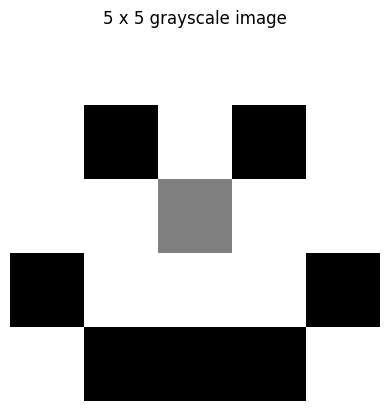

In [46]:
face = np.array([[255, 255, 255, 255, 255],
                 [255,   0, 255,   0, 255],
                 [255, 255, 128, 255, 255],
                 [  0, 255, 255, 255,   0],
                 [255,   0,   0,   0, 255]])

print(face.shape)
plt.imshow(face, cmap="gray", vmin=0, vmax=255)
plt.title("5 x 5 grayscale image"); plt.axis("off")
plt.show()

(5, 5, 3)


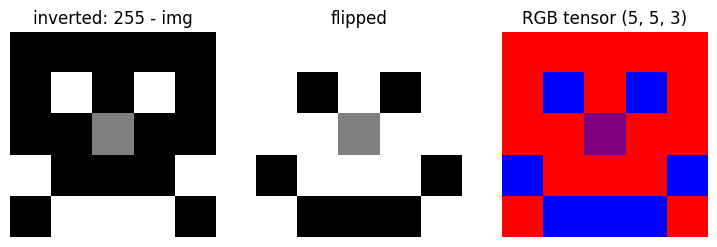

In [47]:
colour = np.zeros((5, 5, 3), dtype=np.uint8)
colour[..., 0] = face
colour[..., 2] = 255 - face
print(colour.shape)

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
ax[0].imshow(255 - face, cmap="gray", vmin=0, vmax=255); ax[0].set_title("inverted: 255 - img")
ax[1].imshow(np.fliplr(face), cmap="gray", vmin=0, vmax=255); ax[1].set_title("flipped")
ax[2].imshow(colour); ax[2].set_title("RGB tensor (5, 5, 3)")
for a in ax: a.axis("off")
plt.show()

Words get ID numbers, then vectors. A **one-hot vector** has a 1 at the word's ID and 0 elsewhere.
Real models learn richer vectors called embeddings.

In [48]:
vocab = ["I", "love", "maths", "ML"]
word_to_id = {w: i for i, w in enumerate(vocab)}

sentence = "I love maths"
ids = [word_to_id[w] for w in sentence.split()]
print(sentence, "->", ids)

one_hot = np.eye(len(vocab), dtype=int)
for w in vocab:
    print(f"{w:6s} id={word_to_id[w]}  {one_hot[word_to_id[w]]}")

I love maths -> [0, 1, 2]
I      id=0  [1 0 0 0]
love   id=1  [0 1 0 0]
maths  id=2  [0 0 1 0]
ML     id=3  [0 0 0 1]


### 2.3 The Dot Product (slide 7)

$$\mathbf{a} \cdot \mathbf{b} = \sum_{i=1}^{n} a_i b_i \qquad [2, 3] \cdot [4, 1] = 2 \times 4 + 3 \times 1 = 8 + 3 = 11$$

Multiply matching items, then add them up. Two lists in, one number out.

In [49]:
def dot(a, b):
    total = 0
    for ai, bi in zip(a, b):
        total += ai * bi
    return total

a = np.array([2, 3])
b = np.array([4, 1])

print(dot(a, b))
print(np.dot(a, b))
print(a @ b)

11
11
11


### 2.4 Matrix Multiplication (slide 7)

$$\begin{bmatrix} 2 & 3 \\ 1 & 5 \end{bmatrix} \begin{bmatrix} 4 \\ 1 \end{bmatrix} = \begin{bmatrix} 2 \times 4 + 3 \times 1 \\ 1 \times 4 + 5 \times 1 \end{bmatrix} = \begin{bmatrix} 11 \\ 9 \end{bmatrix}$$

Inner sizes must match: $(m \times n) \cdot (n \times p) \rightarrow (m \times p)$. Each answer is one row · column, so GPUs run them in parallel.

$$C_{ij} = \sum_{k=1}^{n} A_{ik} B_{kj} = \text{row}_i(A) \cdot \text{col}_j(B)$$

In [50]:
def matmul(A, B):
    m, n = A.shape
    n2, p = B.shape
    assert n == n2, f"inner sizes must match: {A.shape} @ {B.shape}"
    C = np.zeros((m, p), dtype=A.dtype)
    for i in range(m):
        for j in range(p):
            C[i, j] = dot(A[i, :], B[:, j])
    return C

A = np.array([[2, 3],
              [1, 5]])
w = np.array([[4],
              [1]])

for i in range(A.shape[0]):
    print(f"row {i + 1}: {A[i]} . {w[:, 0]} = {dot(A[i], w[:, 0])}")

print(matmul(A, w))
print(A @ w)
print(A.shape, "@", w.shape, "->", (A @ w).shape)

row 1: [2 3] . [4 1] = 11
row 2: [1 5] . [4 1] = 9
[[11]
 [ 9]]
[[11]
 [ 9]]
(2, 2) @ (2, 1) -> (2, 1)


In [51]:
M = np.random.rand(3, 4)
N = np.random.rand(4, 2)
print((M @ N).shape)

try:
    M @ M
except ValueError as e:
    print("ValueError:", e)

(3, 2)
ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 3 is different from 4)


$AB \neq BA$ in general. In NumPy `*` is element-wise and `@` is matrix multiplication. Transpose: $(A^T)_{ij} = A_{ji}$.

In [ ]:
P = np.array([[1, 2], [3, 4]])
Q = np.array([[0, 1], [1, 0]])
print("P @ Q =\n", P @ Q)
print("Q @ P =\n", Q @ P)
print("P * Q =\n", P * Q)
print("P.T   =\n", P.T)

P @ Q =
 [[2 1]
 [4 3]]
Q @ P =
 [[3 4]
 [1 2]]
P * Q =
 [[0 2]
 [3 0]]
P.T   =
 [[1 3]
 [2 4]]


### 2.5 Features × Weights = Prediction (slide 8)

$$\hat{y} = w_1 x_1 + w_2 x_2 + b = \mathbf{w} \cdot \mathbf{x} + b$$

- $\mathbf{x}$: features (size, bedrooms)
- $\mathbf{w}$: weights, how much each input matters
- $b$: bias
- $\hat{y}$: prediction, the estimated price

$$\hat{y} = 20{,}000 \times 1{,}000 + 500{,}000 \times 3 + 1{,}000{,}000 = \text{LKR } 22{,}500{,}000$$

In [53]:
x = np.array([1000, 3])
w = np.array([20000, 500000])
b = 1000000

y_hat = w @ x + b
print(f"LKR {y_hat:,}")

LKR 22,500,000


For a whole table $X$ of shape $(n, d)$, one matrix multiply predicts every row:

$$\hat{\mathbf{y}} = X\mathbf{w} + b$$

In [54]:
X = df[["size_sqft", "bedrooms"]].to_numpy()
y = df["price_lkr"].to_numpy()

y_hat = X @ w + b
print(pd.DataFrame({"actual": y, "predicted": y_hat, "error": y - y_hat}))

     actual  predicted    error
0  18000000   18000000        0
1  22500000   22500000        0
2  26000000   26500000  -500000
3  32000000   33000000 -1000000
4  38000000   39000000 -1000000
5  46000000   47500000 -1500000


Training = finding good weights and bias. Part 03 shows how.

Why vectorize: NumPy runs the same dot product in optimised C instead of a Python loop.

In [55]:
import time

n = 1_000_000
u = np.random.rand(n)
v = np.random.rand(n)

t = time.perf_counter(); s1 = dot(u, v); t_loop = time.perf_counter() - t
t = time.perf_counter(); s2 = u @ v;     t_vec = time.perf_counter() - t

print(f"loop:       {t_loop:.4f}s")
print(f"vectorized: {t_vec:.6f}s  ({t_loop / t_vec:.0f}x faster)")
print(np.isclose(s1, s2))

loop:       0.2037s
vectorized: 0.001585s  (129x faster)
True


### 2.6 Extra: Norms, Distance and Cosine Similarity

$$\|\mathbf{x}\|_1 = \sum_i |x_i| \qquad \|\mathbf{x}\|_2 = \sqrt{\sum_i x_i^2} = \sqrt{\mathbf{x} \cdot \mathbf{x}}$$

$$d_{\text{Manhattan}} = \|\mathbf{a} - \mathbf{b}\|_1 \qquad d_{\text{Euclidean}} = \|\mathbf{a} - \mathbf{b}\|_2 \qquad \cos\theta = \frac{\mathbf{a} \cdot \mathbf{b}}{\|\mathbf{a}\|_2 \, \|\mathbf{b}\|_2}$$

In [56]:
def manhattan(a, b):
    return np.sum(np.abs(a - b))

def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

def cosine_similarity(a, b):
    return (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))

p, q = np.array([1, 2]), np.array([4, 6])
print("Manhattan:", manhattan(p, q))
print("Euclidean:", euclidean(p, q), np.linalg.norm(p - q))

i_vec, love_vec = one_hot[0], one_hot[1]
print("cos(one-hot I, one-hot love):", cosine_similarity(i_vec, love_vec))
print("cos([2,3], [4,1]):", round(cosine_similarity(np.array([2, 3]), np.array([4, 1])), 3))

Manhattan: 7
Euclidean: 5.0 5.0
cos(one-hot I, one-hot love): 0.0
cos([2,3], [4,1]): 0.74


### 2.7 Extra: Identity, Inverse, Singularity

$$I\mathbf{x} = \mathbf{x} \qquad A A^{-1} = I \qquad \det\begin{bmatrix} a & b \\ c & d \end{bmatrix} = ad - bc$$

If $\det(A) = 0$ the matrix is singular and has no inverse.

In [57]:
print(np.eye(2) @ A)
print("det(A) =", round(np.linalg.det(A), 3))
print("A @ inv(A) =\n", A @ np.linalg.inv(A))

S = np.array([[1, 2],
              [2, 4]])
print("det(S) =", np.linalg.det(S))
try:
    np.linalg.inv(S)
except np.linalg.LinAlgError as e:
    print("LinAlgError:", e)

[[2. 3.]
 [1. 5.]]
det(A) = 7.0
A @ inv(A) =
 [[1. 0.]
 [0. 1.]]
det(S) = 0.0
LinAlgError: Singular matrix


## Part 03 — Calculus & Optimization

### 3.1 What Does Learning Mean? (slide 9)

Learning = adjusting the weights to make fewer mistakes.

1. Make a prediction with the current weights
2. Measure the error (loss)
3. Find the direction that lowers the error (gradient)
4. Nudge the weights a little that way
5. Repeat until the error stops shrinking

### 3.2 Derivatives (slide 10)

A derivative is a slope: how fast one thing changes when another changes.

$$f'(x) = \lim_{h \to 0} \frac{f(x + h) - f(x)}{h} \qquad f(x) = x^2 \Rightarrow f'(x) = 2x \Rightarrow f'(3) = 6, \; f'(0) = 0$$

Sign: $+$ going up, $-$ going down, $0$ flat. Average rate of change: $120 \text{ km} / 2 \text{ h} = 60 \text{ km/h}$.

In [58]:
def f(x):
    return x ** 2

def numerical_derivative(f, x, h=1e-5):
    return (f(x + h) - f(x - h)) / (2 * h)

for x0 in [-2, 0, 3]:
    print(f"x = {x0:2d}  numerical = {numerical_derivative(f, x0):6.3f}  analytic 2x = {2 * x0}")

print("average speed:", 120 / 2, "km/h")

x = -2  numerical = -4.000  analytic 2x = -4
x =  0  numerical =  0.000  analytic 2x = 0
x =  3  numerical =  6.000  analytic 2x = 6
average speed: 60.0 km/h


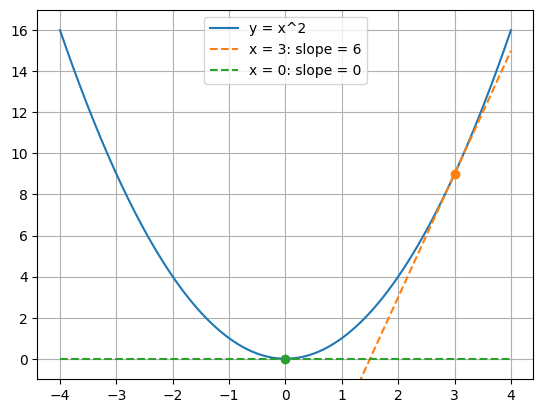

In [59]:
xs = np.linspace(-4, 4, 200)
plt.plot(xs, f(xs), label="y = x^2")
for x0, colour in [(3, "tab:orange"), (0, "tab:green")]:
    slope = 2 * x0
    plt.plot(xs, f(x0) + slope * (xs - x0), "--", color=colour, label=f"x = {x0}: slope = {slope}")
    plt.scatter([x0], [f(x0)], color=colour, zorder=3)
plt.ylim(-1, 17); plt.grid(True); plt.legend()
plt.show()

With several weights, take one **partial derivative** per weight. Together they form the **gradient**:

$$\nabla L = \left[\frac{\partial L}{\partial w_1}, \frac{\partial L}{\partial w_2}, \dots\right]$$

The gradient points uphill; we step the opposite way.

### 3.3 Cost / Loss Function: MSE (slide 11)

Loss = error on one example. Cost = average over the whole dataset. Lower = better.

1. Error: $y - \hat{y}$
2. Square it: no negatives, big misses count more
3. Average:

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

In [60]:
y_true = np.array([3, 5, 7])
y_pred = np.array([2, 5, 9])

error = y_true - y_pred
squared = error ** 2
print("error:  ", error)
print("squared:", squared)
print("MSE:    ", squared.sum(), "/", len(squared), "=", round(squared.mean(), 2))

def mse(y, y_hat):
    return np.mean((y - y_hat) ** 2)

print(round(mse(y_true, y_pred), 2))

error:   [ 1  0 -2]
squared: [1 0 4]
MSE:     5 / 3 = 1.67
1.67


### 3.4 Gradient Descent (slide 12)

$$w_{\text{new}} = w_{\text{old}} - \alpha \times \text{slope}$$

$\alpha$ = learning rate (step size). Example: cost $= w^2$, slope $= 2w$, $\alpha = 0.1$, start $w = 3$:

$$\text{step 1: } 3 - 0.1 \times 6 = 2.4$$

Repeat until steps get tiny (converged).

step 1: 3.0000 - 0.1 x 6.0000 = 2.4000
step 2: 2.4000 - 0.1 x 4.8000 = 1.9200
step 3: 1.9200 - 0.1 x 3.8400 = 1.5360
step 4: 1.5360 - 0.1 x 3.0720 = 1.2288
step 5: 1.2288 - 0.1 x 2.4576 = 0.9830
after 20 steps: w = 0.0346, cost = 0.001196


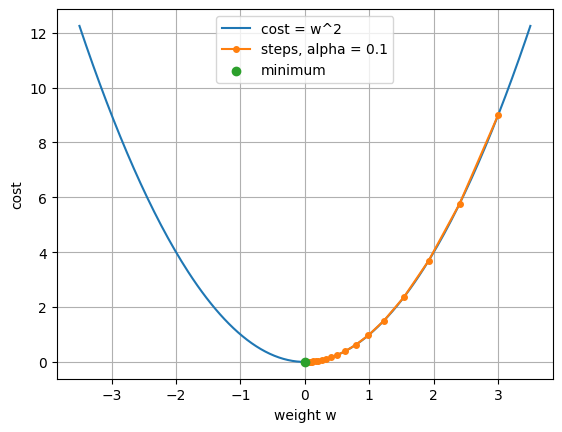

In [61]:
def cost(w):
    return w ** 2

def slope(w):
    return 2 * w

def gradient_descent(w, lr, steps):
    history = [w]
    for _ in range(steps):
        w = w - lr * slope(w)
        history.append(w)
    return np.array(history)

hist = gradient_descent(w=3.0, lr=0.1, steps=20)
for i in range(5):
    print(f"step {i + 1}: {hist[i]:.4f} - 0.1 x {slope(hist[i]):.4f} = {hist[i + 1]:.4f}")
print(f"after 20 steps: w = {hist[-1]:.4f}, cost = {cost(hist[-1]):.6f}")

ws = np.linspace(-3.5, 3.5, 200)
plt.plot(ws, cost(ws), label="cost = w^2")
plt.plot(hist, cost(hist), "o-", color="tab:orange", ms=4, label="steps, alpha = 0.1")
plt.scatter([0], [0], color="tab:green", zorder=3, label="minimum")
plt.xlabel("weight w"); plt.ylabel("cost"); plt.grid(True); plt.legend()
plt.show()

### 3.5 Learning Rate $\alpha$ (slide 13)

- Too small: tiny steps, training is very slow
- Too big: overshoots the minimum, bounces around or diverges
- Just right: moves smoothly down to the minimum

Common values to try first: $0.1, 0.01, 0.001$.

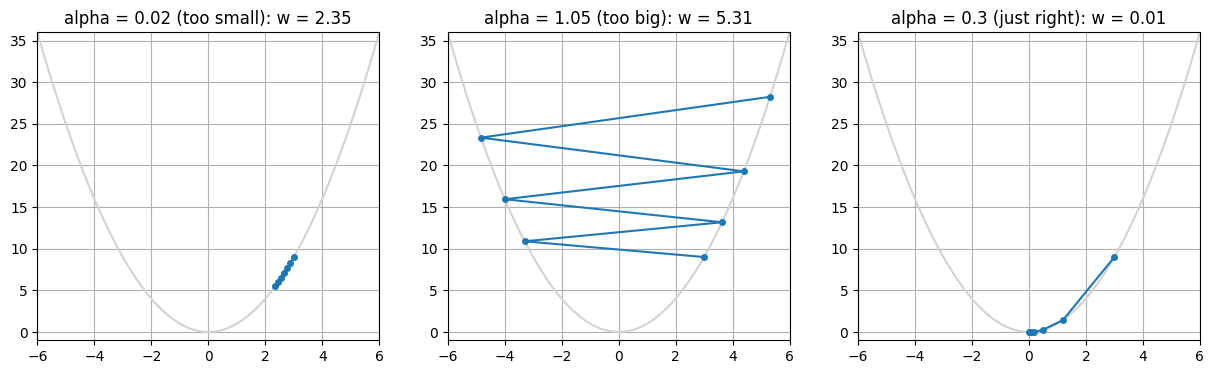

In [62]:
wide = np.linspace(-6, 6, 200)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lr, title in zip(axes, [0.02, 1.05, 0.3], ["too small", "too big", "just right"]):
    h = gradient_descent(w=3.0, lr=lr, steps=6)
    ax.plot(wide, cost(wide), color="lightgray")
    ax.plot(h, cost(h), "o-", ms=4)
    ax.set_title(f"alpha = {lr} ({title}): w = {h[-1]:.2f}")
    ax.set_xlim(-6, 6); ax.set_ylim(-1, 36); ax.grid(True)
plt.show()

### 3.6 The Full Learning Loop

Model $\hat{y} = wx + b$, cost MSE. Gradients:

$$\frac{\partial L}{\partial w} = -\frac{2}{n}\sum_{i=1}^{n} x_i\,(y_i - \hat{y}_i) \qquad \frac{\partial L}{\partial b} = -\frac{2}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)$$

$$w \leftarrow w - \alpha\,\frac{\partial L}{\partial w} \qquad b \leftarrow b - \alpha\,\frac{\partial L}{\partial b}$$

Features are scaled first (size in 1000s of sq ft, price in millions LKR) so one learning rate works.

w = 19.848 M LKR per 1000 sq ft, b = 2.299 M LKR
MSE: 1015.04 -> 0.0294
prediction for 1,600 sq ft: LKR 34,055,420


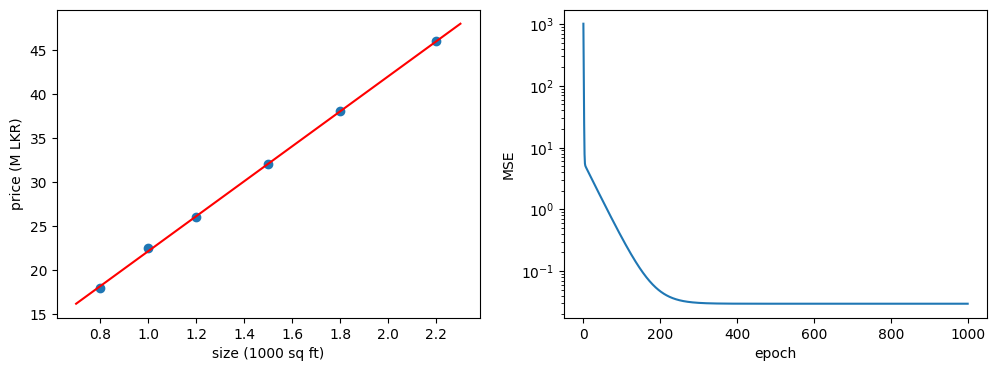

In [63]:
x = df["size_sqft"].to_numpy() / 1000
y = df["price_lkr"].to_numpy() / 1e6

w, b = 0.0, 0.0
lr = 0.1
losses = []

for epoch in range(1000):
    y_hat = w * x + b
    error = y - y_hat
    losses.append(np.mean(error ** 2))
    dw = -2 * np.mean(x * error)
    db = -2 * np.mean(error)
    w -= lr * dw
    b -= lr * db

print(f"w = {w:.3f} M LKR per 1000 sq ft, b = {b:.3f} M LKR")
print(f"MSE: {losses[0]:.2f} -> {losses[-1]:.4f}")
print(f"prediction for 1,600 sq ft: LKR {(w * 1.6 + b) * 1e6:,.0f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(x, y)
xx = np.linspace(0.7, 2.3, 50)
ax[0].plot(xx, w * xx + b, color="red")
ax[0].set_xlabel("size (1000 sq ft)"); ax[0].set_ylabel("price (M LKR)")
ax[1].plot(losses); ax[1].set_yscale("log")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("MSE")
plt.show()

## Part 04 — Probability & Statistics

### 4.1 Mean, Median, Spread (slide 14)

Cups of coffee sold on 8 days: $2, 4, 4, 4, 5, 5, 7, 9$

$$\mu = \frac{1}{n}\sum x_i = \frac{40}{8} = 5 \qquad \text{median} = \frac{4 + 5}{2} = 4.5$$

$$\sigma^2 = \frac{1}{n}\sum (x_i - \mu)^2 = \frac{32}{8} = 4 \qquad \sigma = \sqrt{4} = 2$$

Sample variance divides by $n - 1$: $s^2 = 32 / 7 \approx 4.57$

In [64]:
coffee = np.array([2, 4, 4, 4, 5, 5, 7, 9])
n = len(coffee)

mean = coffee.sum() / n
sq_dev = (coffee - mean) ** 2

print("mean:           ", coffee.sum(), "/", n, "=", mean)
print("median:         ", np.median(coffee))
print("variance (pop): ", sq_dev.sum(), "/", n, "=", sq_dev.sum() / n)
print("std (pop):      ", np.sqrt(sq_dev.sum() / n))
print("variance (samp):", sq_dev.sum(), "/", n - 1, "=", round(sq_dev.sum() / (n - 1), 2))
print("numpy:", np.mean(coffee), np.var(coffee), np.std(coffee), round(np.var(coffee, ddof=1), 2))

mean:            40 / 8 = 5.0
median:          4.5
variance (pop):  32.0 / 8 = 4.0
std (pop):       2.0
variance (samp): 32.0 / 7 = 4.57
numpy: 5.0 4.0 2.0 4.57


In [65]:
with_outlier = np.append(coffee, 100)
print("mean:  ", coffee.mean(), "->", round(with_outlier.mean(), 2))
print("median:", np.median(coffee), "->", np.median(with_outlier))

mean:   5.0 -> 15.56
median: 4.5 -> 5.0


The median barely moves with an outlier; the mean jumps.

### 4.2 The Normal Distribution (slide 15)

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}}\, e^{-\frac{(x - \mu)^2}{2\sigma^2}}$$

68-95-99.7 rule: about 68% within $\pm 1\sigma$, 95% within $\pm 2\sigma$, 99.7% within $\pm 3\sigma$.

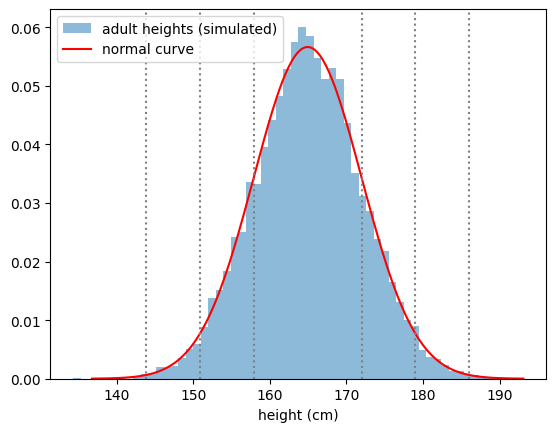

within +-1 sigma: 0.682
within +-2 sigma: 0.955
within +-3 sigma: 0.997


In [66]:
def normal_pdf(x, mu, sigma):
    return np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi))

rng = np.random.default_rng(42)
heights = rng.normal(loc=165, scale=7, size=10_000)
mu, sigma = heights.mean(), heights.std()

xs = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 300)
plt.hist(heights, bins=60, density=True, alpha=0.5, label="adult heights (simulated)")
plt.plot(xs, normal_pdf(xs, mu, sigma), color="red", label="normal curve")
for k in [1, 2, 3]:
    plt.axvline(mu - k * sigma, color="gray", ls=":")
    plt.axvline(mu + k * sigma, color="gray", ls=":")
plt.xlabel("height (cm)"); plt.legend()
plt.show()

for k in [1, 2, 3]:
    print(f"within +-{k} sigma: {np.mean(np.abs(heights - mu) < k * sigma):.3f}")

Why it matters in ML:

- Linear regression's classic assumptions include roughly normal errors.
- Standardising features helps training: $z = \dfrac{x - \mu}{\sigma}$
- Values more than about $3\sigma$ from the mean are rare ($\approx 0.3\%$), so they flag possible outliers.

In [67]:
z = (df[["size_sqft", "bedrooms"]] - df[["size_sqft", "bedrooms"]].mean()) / df[["size_sqft", "bedrooms"]].std(ddof=0)
print(z.round(2))
print("mean:", z.mean().round(3).tolist(), " std:", z.std(ddof=0).round(3).tolist())

   size_sqft  bedrooms
0      -1.29     -1.57
1      -0.87     -0.52
2      -0.45     -0.52
3       0.17      0.52
4       0.80      0.52
5       1.64      1.57
mean: [-0.0, 0.0]  std: [1.0, 1.0]


In [68]:
readings = np.append(rng.normal(50, 5, 200), [85, 12])
z_r = (readings - readings.mean()) / readings.std()
print("possible outliers (|z| > 3):", readings[np.abs(z_r) > 3].round(1))

possible outliers (|z| > 3): [85. 12.]


### 4.3 ML Is a Probability Game (slide 16)

Models estimate how likely each outcome is, from patterns in past data.

$$0 \le P(A) \le 1 \qquad \sum_k P(\text{class}_k) = 1$$

A threshold (for example $0.5$) turns a probability into a yes/no decision.

In [69]:
outputs = {"spam filter: spam": 0.92, "weather: rain": 0.70, "loan: repay": 0.78}
threshold = 0.5
for name, p in outputs.items():
    print(f"{name:20s} p = {p:.2f} -> {'yes' if p >= threshold else 'no'}")

classifier = {"cat": 0.85, "dog": 0.12, "other": 0.03}
print("image classifier:", classifier, "sum =", round(sum(classifier.values()), 2))
print("prediction:", max(classifier, key=classifier.get))

spam filter: spam    p = 0.92 -> yes
weather: rain        p = 0.70 -> yes
loan: repay          p = 0.78 -> yes
image classifier: {'cat': 0.85, 'dog': 0.12, 'other': 0.03} sum = 1.0
prediction: cat


Probability as long-run frequency: $P(A) \approx \dfrac{\text{count}(A)}{\text{total}}$

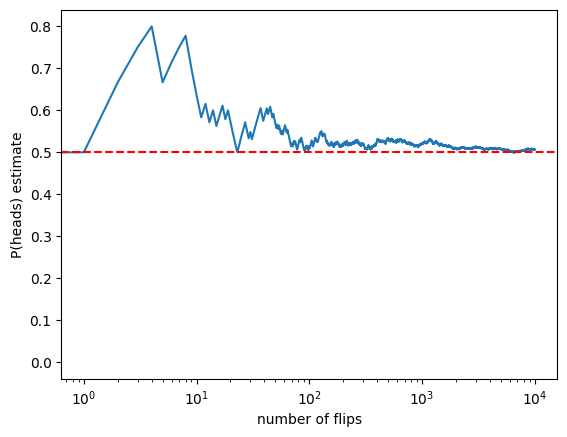

estimate after 10,000 flips: 0.5068


In [70]:
flips = rng.integers(0, 2, size=10_000)
running = np.cumsum(flips) / np.arange(1, len(flips) + 1)

plt.plot(running)
plt.axhline(0.5, color="red", ls="--")
plt.xscale("log"); plt.xlabel("number of flips"); plt.ylabel("P(heads) estimate")
plt.show()
print("estimate after 10,000 flips:", running[-1])

## Part 05 — NumPy & Pandas in Action

### 5.1 NumPy (slide 17)

Same numbers as slide 7. `np.array` makes vectors and matrices, `.shape` shows the size, `np.dot(x, w)` or `A @ w` does the dot product and matrix multiply.

In [71]:
import numpy as np

x = np.array([2, 3])
A = np.array([[2, 3],
              [1, 5]])
w = np.array([4, 1])

print(x.shape, A.shape)
print(np.dot(x, w))
print(A @ w)

(2,) (2, 2)
11
[11  9]


In [72]:
arr = np.arange(12).reshape(3, 4)
print(arr)
print("row 0:     ", arr[0])
print("column 1:  ", arr[:, 1])
print("> 5:       ", arr[arr > 5])
print("sum axis 0:", arr.sum(axis=0))
print("mean:      ", arr.mean())

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
row 0:      [0 1 2 3]
column 1:   [1 5 9]
> 5:        [ 6  7  8  9 10 11]
sum axis 0: [12 15 18 21]
mean:       5.5


### 5.2 Pandas (slide 18)

1. `df.head()`: first 5 rows
2. `df.shape`: (rows, columns)
3. `df.describe()`: mean, std, min, max, quartiles

`describe()` gives the **sample** std (divides by $n - 1$); `np.std` defaults to population (divides by $n$).

In [73]:
import pandas as pd

df = pd.read_csv("houses.csv")
print(df.head())
print(df.shape)
print(df.describe())

   size_sqft  bedrooms  price_lkr
0        800         2   18000000
1       1000         3   22500000
2       1200         3   26000000
3       1500         4   32000000
4       1800         4   38000000
(6, 3)
         size_sqft  bedrooms     price_lkr
count     6.000000  6.000000  6.000000e+00
mean   1416.666667  3.500000  3.041667e+07
std     523.131596  1.048809  1.038468e+07
min     800.000000  2.000000  1.800000e+07
25%    1050.000000  3.000000  2.337500e+07
50%    1350.000000  3.500000  2.900000e+07
75%    1725.000000  4.000000  3.650000e+07
max    2200.000000  5.000000  4.600000e+07


In [74]:
print("pandas std (n-1):", round(df["size_sqft"].std(), 2))
print("numpy  std (n):  ", round(np.std(df["size_sqft"]), 2))
print("numpy  std (n-1):", round(np.std(df["size_sqft"], ddof=1), 2))

coffee_df = pd.DataFrame({"cups": coffee})
print(coffee_df.describe().T)

pandas std (n-1): 523.13
numpy  std (n):   477.55
numpy  std (n-1): 523.13
      count  mean      std  min  25%  50%  75%  max
cups    8.0   5.0  2.13809  2.0  4.0  4.5  5.5  9.0


In [75]:
df["price_per_sqft"] = df["price_lkr"] / df["size_sqft"]
print(df[df["bedrooms"] >= 4])
print(df.groupby("bedrooms")["price_lkr"].mean())

X = df[["size_sqft", "bedrooms"]].to_numpy()
w = np.array([20000, 500000])
b = 1000000
df["predicted"] = X @ w + b
print(df[["size_sqft", "bedrooms", "price_lkr", "predicted"]])
print(f"MSE: {mse(df['price_lkr'], df['predicted']):,.0f}")

   size_sqft  bedrooms  price_lkr  price_per_sqft
3       1500         4   32000000    21333.333333
4       1800         4   38000000    21111.111111
5       2200         5   46000000    20909.090909
bedrooms
2    18000000.0
3    24250000.0
4    35000000.0
5    46000000.0
Name: price_lkr, dtype: float64
   size_sqft  bedrooms  price_lkr  predicted
0        800         2   18000000   18000000
1       1000         3   22500000   22500000
2       1200         3   26000000   26500000
3       1500         4   32000000   33000000
4       1800         4   38000000   39000000
5       2200         5   46000000   47500000
MSE: 750,000,000,000


## Wrap-Up (slide 19)

| Topic | Key idea |
|---|---|
| Data as numbers | vectors, matrices, tensors and the dot product |
| How a model learns | cost function + gradient descent + learning rate |
| Stats + code | mean, spread, the normal curve; NumPy & Pandas |

**The big idea:** learning = finding the weights that make the cost small, one step at a time.

**Next week (slide 20):** Linear Regression, $\hat{y} = wx + b$, fitted with the dot product, MSE and gradient descent.

## Practice

1. Compute $[1, 2, 3] \cdot [4, 5, 6]$ by hand, then with NumPy.
2. Which products are valid: $(3 \times 2)(2 \times 4)$, $(2 \times 3)(2 \times 3)$, $(4 \times 1)(1 \times 4)$? Give the output shapes.
3. With $\mathbf{w} = [20000, 500000]$ and $b = 1{,}000{,}000$, predict the price of a 1,400 sq ft, 3-bedroom house.
4. Compute the MSE for actual $[4, 6, 8]$ and predicted $[5, 6, 6]$.
5. Run gradient descent on cost $= w^2$ from $w = -4$ with $\alpha = 0.1$, $0.02$ and $1.05$. What happens each time?
6. For $[10, 12, 23, 23, 16, 23, 21, 16]$ compute mean, median, population and sample std, then check with `df.describe()`.